# W4：模型进阶与集成

**对应 D7–D11（10-19 至 10-23）· 约 17 小时**

W3 那一周把流程搭完了：特征工程、时序特征、时序切分、基线、KNN 和逻辑回归。最好的 KNN 只到 R² 0.34，而直接抄上一小时有 0.94。

| Day | 主题 | 时长 | 难度 |
| --- | --- | --- | --- |
| D7 | 决策树 | 约 3h | 常规 |
| D8 | Bagging 与随机森林 | 约 3h | 常规 |
| D9 | 模型对比与残差分析 | 约 3h | 常规 |
| D10 | ★ Boosting：AdaBoost / GBDT / XGBoost | 3.5–4.5h | 硬骨头 |
| D11 | ★ 随机调参 / 时序 CV / 模型融合 | 3.5–4.5h | 硬骨头 |


# 一、共用准备


## 1.1 导入与数据重建

W4 是独立的 notebook，不能指望 W3 的变量还在，所以先把表重建

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer,make_column_transformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn import set_config
set_config(display="text")

from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor)
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

from sklearn.model_selection import (
    train_test_split,
    TimeSeriesSplit,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    roc_auc_score,
)
from scipy.stats import randint, uniform, loguniform

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.unicode_minus"] = False

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.unicode.east_asian_width", True)
RANDOM_STATE = 42
import sklearn
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1.2 重建 feats 表与切分

直接复制

In [2]:
DATA_PATH = "data/PRSA_data_2010.1.1-2014.12.31.csv"

df = pd.read_csv(DATA_PATH)
df = df.dropna(subset=["pm2.5"]).reset_index(drop=True)
print("dropna(pm2.5) 后:", df.shape)

df['datetime'] = pd.to_datetime(df[['year','month','day','hour']])
df = df.set_index('datetime')

df['hour_sin'] = np.sin(2*np.pi*df['hour']/24)
df['hour_cos'] = np.cos(2*np.pi*df['hour']/24)
df['lag1'] = df['pm2.5'].shift(1)
df['lag24'] = df['pm2.5'].shift(24)
df['roll_mean_3'] = df['pm2.5'].shift(1).rolling(3).mean()
df['roll_mean_24'] = df['pm2.5'].shift(1).rolling(24).mean()
df['roll_std_24'] = df['pm2.5'].shift(1).rolling(24).std()

num = ['DEWP','TEMP','PRES','Iws','Is','Ir']
cat = ['cbwd']
construct_cols = ['lag1','lag24','roll_mean_3','roll_mean_24','roll_std_24']
feat_cols = construct_cols + ['hour_sin','hour_cos'] + num + cat

feats = df.dropna(subset=construct_cols)
for c in num:
    feats[c] = feats[c].fillna(feats[c].median())
for c in cat:
    feats[c] = feats[c].fillna(feats[c].mode()[0])

train = feats[feats.index.year<=2013]
test = feats[feats.index.year==2014]

pipe_num = make_pipeline(SimpleImputer(strategy="median"),StandardScaler())
pipe_cat = make_pipeline(OneHotEncoder(handle_unknown="ignore"))
num_all = construct_cols + ['hour_sin','hour_cos'] + num
pre_all = make_column_transformer((pipe_num, num_all),
                                  (pipe_cat,cat))

print(feats.shape, train.shape, test.shape)
print(feat_cols)

dropna(pm2.5) 后: (41757, 13)
(41733, 20) (33072, 20) (8661, 20)
['lag1', 'lag24', 'roll_mean_3', 'roll_mean_24', 'roll_std_24', 'hour_sin', 'hour_cos', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir', 'cbwd']


## 1.3 统一的评分函数

这一周要评很多模型，写一个函数免得每次都抄一遍四行。


In [3]:
def reg_scores(name, model, cols=None):
    cols = feat_cols if cols is None else cols
    model.fit(train[cols], train['pm2.5'])
    t0 = time.time()
    p = model.predict(test[cols])
    cost = time.time() - t0
    return [name,
            round(np.sqrt(mean_squared_error(ytest, p)), 3),
            round(r2_score(ytest, p), 4),
            round(mean_absolute_error(ytest, p), 3),
            round(cost, 2)]


def reg_row(name, model, cols=None):
    r = reg_scores(name, model, cols)
    return {'模型': r[0], 'RMSE': r[1], 'R2': r[2], 'MAE': r[3], '预测耗时': r[4]}

## 1.4 两个基线

后面每加一个模型都要跟它们比，数字和 W3 结果表一致。

In [4]:
Xtrain = train[feat_cols]
ytrain = train['pm2.5']
Xtest = test[feat_cols]
ytest = test['pm2.5']

pred = test['lag1']
Baseline_rmse = np.sqrt(mean_squared_error(test['pm2.5'],pred))
Baseline_score = r2_score(test['pm2.5'],pred)

Mean_pred = np.full(len(test), train['pm2.5'].mean())
Mean_rmse = np.sqrt(mean_squared_error(test['pm2.5'], Mean_pred))

print('均值基线    ', Mean_rmse, 0.0)
print('持久性基线  ', Baseline_rmse, Baseline_score)

均值基线     93.53229935043586 0.0
持久性基线   22.136457386885123 0.9439790683721084


# 二、决策树

**对应 D7（10-19）· 约 3h · 常规**



## 2.1 树在做什么


造一条 `y = 10x + 噪声` 的数据

把切点和两边的预测值打出来，和数据的真实关系放一起看。

切点 5.54
左边预测值 26.50，右边预测值 75.52


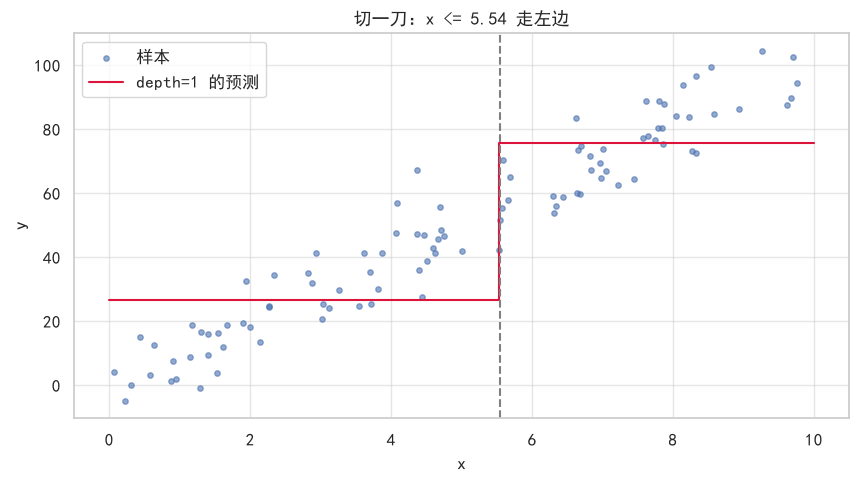

In [37]:
rng = np.random.default_rng(RANDOM_STATE)
x_toy = np.sort(rng.uniform(0, 10, 100))
y_toy = 10*x_toy + rng.normal(0, 8, 100)

tree1 = DecisionTreeRegressor(max_depth=1, random_state=RANDOM_STATE)
tree1.fit(x_toy.reshape(-1,1), y_toy)

thr = tree1.tree_.threshold[0]
print('切点 %.2f' % thr)
print('左边预测值 %.2f，右边预测值 %.2f' % (tree1.tree_.value[1][0][0], tree1.tree_.value[2][0][0]))

plt.scatter(x_toy, y_toy, s=15, alpha=.6, label='样本')
xx = np.linspace(0, 10, 300).reshape(-1,1)
plt.step(xx.ravel(), tree1.predict(xx), where='mid', color='crimson', label='depth=1 的预测')
plt.axvline(thr, color='gray', ls='--')
plt.xlabel('x')
plt.ylabel('y')
plt.title('切一刀：x <= %.2f 走左边' % thr)
plt.legend()
plt.show()

 树的预测值永远只有有限几个，线性回归能输出任意实数，但是树只能输出叶子里的均值。

## 2.2 树不需要标准化

W3 的 KNN 必须标准化，因为它算距离。决策树不需要，因为任何单调变换都不改变排序，所以也不改变树能切出的位置。

用同一个 `max_depth=4` 的树，一次用原始特征，一次用标准化后的特征，看预测是否完全一致。

In [6]:
cols_num = num_all

Xt_raw = train[cols_num]
Xt_sc = StandardScaler().fit_transform(Xt_raw)

t_raw = DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE)
t_raw.fit(Xt_raw, train['pm2.5'])
t_sc = DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE)
t_sc.fit(Xt_sc, train['pm2.5'])

print('标准化前后预测完全一致:', np.allclose(t_raw.predict(Xt_raw), t_sc.predict(Xt_sc)))
print('Iws 范围 %.1f ~ %.1f' % (Xt_raw['Iws'].min(), Xt_raw['Iws'].max()))
print('PRES 范围 %.1f ~ %.1f' % (Xt_raw['PRES'].min(), Xt_raw['PRES'].max()))

标准化前后预测完全一致: True
Iws 范围 0.5 ~ 565.5
PRES 范围 991.0 ~ 1046.0


结果是 `True`。树的本质是通过计算切点两边的预测值的离差平方和的和最小，所以数值一起标准化并不影响计算

## 2.3 深度与过拟合

遍历 `max_depth` 从 1 到 20，同时记录训练集和测试集的 R²。

测试集 R2 最优深度 = 4  R2 = 0.9350


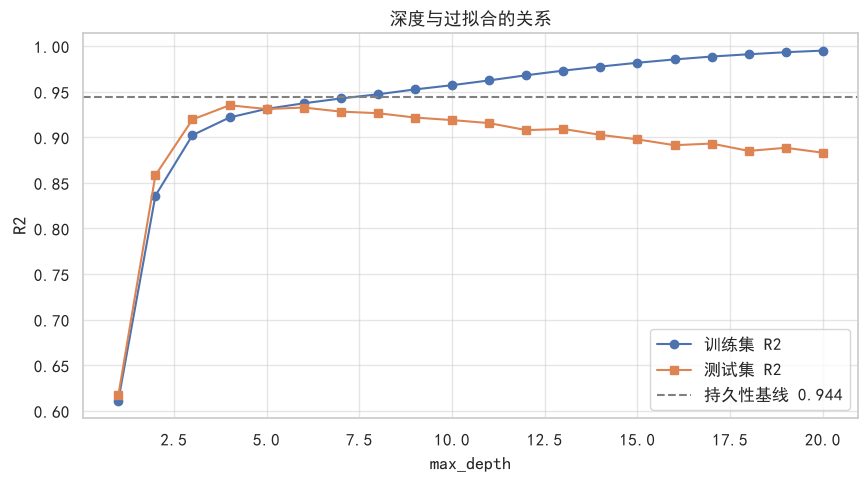

,深度,训练R2,测试R2,叶子数
0,1,0.6112,0.6170,2
1,2,0.8358,0.8582,4
2,3,0.9022,0.9194,8
3,4,0.9216,0.9350,16
4,5,0.9311,0.9309,32
5,6,0.9372,0.9325,62
6,7,0.9425,0.9280,119
7,8,0.9470,0.9263,223
8,9,0.9524,0.9215,399
9,10,0.9570,0.9188,666


In [38]:
Xtr_pre = pre_all.fit_transform(Xtrain)
Xte_pre = pre_all.transform(Xtest)

depths = list(range(1, 21))
tr_r2 = []
te_r2 = []
n_leaves = []

for d in depths:
    m = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE)
    m.fit(Xtr_pre, ytrain)
    tr_r2.append(r2_score(ytrain, m.predict(Xtr_pre)))
    te_r2.append(r2_score(ytest, m.predict(Xte_pre)))
    n_leaves.append(m.get_n_leaves())

best_d = depths[int(np.argmax(te_r2))]
print('测试集 R2 最优深度 = %d  R2 = %.4f' % (best_d, max(te_r2)))

plt.plot(depths, tr_r2, 'o-', label='训练集 R2')
plt.plot(depths, te_r2, 's-', label='测试集 R2')
plt.axhline(Baseline_score, color='gray', ls='--', label='持久性基线 %.3f' % Baseline_score)
plt.xlabel('max_depth')
plt.ylabel('R2')
plt.title('深度与过拟合的关系')
plt.legend()
plt.show()

depth_df = pd.DataFrame({'深度': depths,
                         '训练R2': np.round(tr_r2, 4),
                         '测试R2': np.round(te_r2, 4),
                         '叶子数': n_leaves})
depth_df

## 2.4 树的另一个性质：它不能预测出比原来最大值更大的样本

树的所有预测值都是训练集里出现过的目标值的平均，所以它永远不可能预测出比训练集最大值还大的数。
把300以上的样本在训练集中去掉，再测试一下

In [39]:
tree8 = DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE)
tree8.fit(Xtr_pre, ytrain)
p8 = tree8.predict(Xte_pre)

print('训练集 pm2.5 最大值: %.1f' % train['pm2.5'].max())
print('树在测试集上的预测最大值: %.1f' % p8.max())

y_clip = train['pm2.5'].clip(upper=300)
tree_clip = DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE)
tree_clip.fit(Xtr_pre, y_clip)
p_clip = tree_clip.predict(Xte_pre)

print('截断后训练集最大值: %.1f' % y_clip.max())
print('截断后的模型预测最大值: %.1f' % p_clip.max())
print('测试集真实值超过 300 的条数: %d' % (test['pm2.5'] > 300).sum())

训练集 pm2.5 最大值: 994.0
树在测试集上的预测最大值: 980.0
截断后训练集最大值: 300.0
截断后的模型预测最大值: 300.0
测试集真实值超过 300 的条数: 456


## 2.5 单棵树放上结果表

`max_depth` 用 2.3 找出的最优值，接上 `pre_all` 走一遍完整流程。

另外单独测一个只用原始 6 个气象特征的版本，和持久性基线比。

In [9]:
dt3 = make_pipeline(pre_all, DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE))
dt3.fit(Xtrain, ytrain)
dt3_rmse = np.sqrt(mean_squared_error(ytest, dt3.predict(Xtest)))
dt3_score = r2_score(ytest, dt3.predict(Xtest))

dt_best = make_pipeline(pre_all, DecisionTreeRegressor(max_depth=best_d, random_state=RANDOM_STATE))
dt_best.fit(Xtrain, ytrain)
dt_rmse = np.sqrt(mean_squared_error(ytest, dt_best.predict(Xtest)))
dt_score = r2_score(ytest, dt_best.predict(Xtest))

print('基线            ', Baseline_rmse, Baseline_score)
print('决策树 depth=3  ', dt3_rmse, dt3_score)
print('决策树 depth=%d  ' % best_d, dt_rmse, dt_score)

基线             22.136457386885123 0.9439790683721084
决策树 depth=3   26.546104205184808 0.9194369912566389
决策树 depth=4   23.845214656716568 0.934996527079134


`feature_importances_` 是所有树模型自带的输出，含义是这个特征在所有切分中让不纯度下降了多少，按样本数加权。

它和线性回归的 `coef_` 很像，但系数有方向，正相关还是负相关；重要度没有方向，只说明这个特征被用得多不多。


depth=4 的树有 16 个叶子
lag1 1.0
lag24 0.0
roll_mean_3 0.0
roll_mean_24 0.0
roll_std_24 0.0
hour_sin 0.0
hour_cos 0.0
DEWP 0.0

depth=12 的树
lag1 0.9607
roll_mean_3 0.0088
DEWP 0.0062
roll_mean_24 0.0045
Iws 0.0036
PRES 0.003
roll_std_24 0.0029
hour_sin 0.0024
TEMP 0.0019
lag24 0.0018


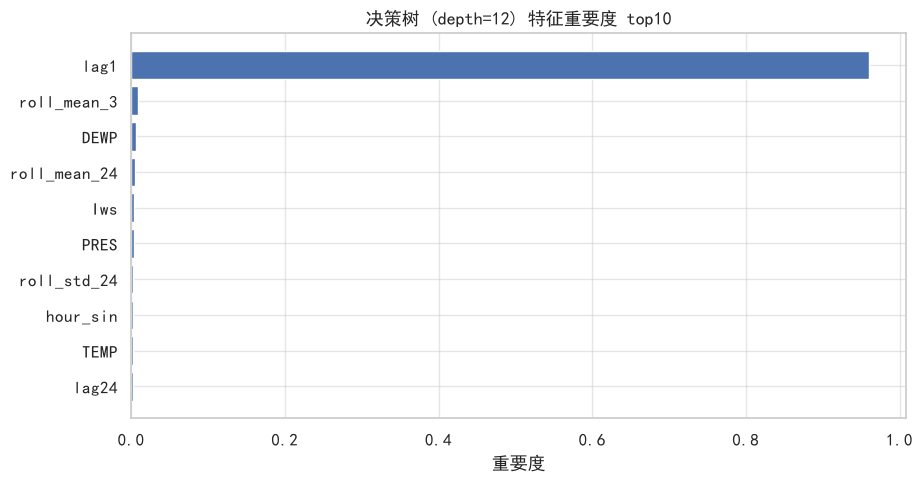

In [10]:
tree_best = DecisionTreeRegressor(max_depth=best_d, random_state=RANDOM_STATE)
tree_best.fit(Xtr_pre, ytrain)
names = pre_all.get_feature_names_out()
imp = tree_best.feature_importances_
top = sorted(zip(names, imp), key=lambda x: -x[1])[:8]
top = [(n.split('__')[-1], v) for n, v in top]

print('depth=%d 的树有 %d 个叶子' % (best_d, tree_best.get_n_leaves()))
for n, v in top:
    print(n, round(v, 4))

tree_deep = DecisionTreeRegressor(max_depth=12, random_state=RANDOM_STATE)
tree_deep.fit(Xtr_pre, ytrain)
imp_deep = tree_deep.feature_importances_
top_deep = sorted(zip(names, imp_deep), key=lambda x: -x[1])[:10]
top_deep = [(n.split('__')[-1], v) for n, v in top_deep]

print()
print('depth=12 的树')
for n, v in top_deep:
    print(n, round(v, 4))

names_bar = []
vals_bar = []
for n, v in top_deep:
    names_bar.append(n)
    vals_bar.append(v)

plt.barh(names_bar[::-1], vals_bar[::-1])
plt.xlabel('重要度')
plt.title('决策树 (depth=12) 特征重要度 top10')
plt.show()

重要度对高基数特征有偏好，取值很多的连续列切分点多了总能找到让训练集更纯的位置。`Iws`、`PRES` 这类连续列的重要度天然偏高，不代表它们真的更有用。

## 2.6 画一棵树

`plot_tree` 把一棵树的判断过程画出来。

只取前 2 层

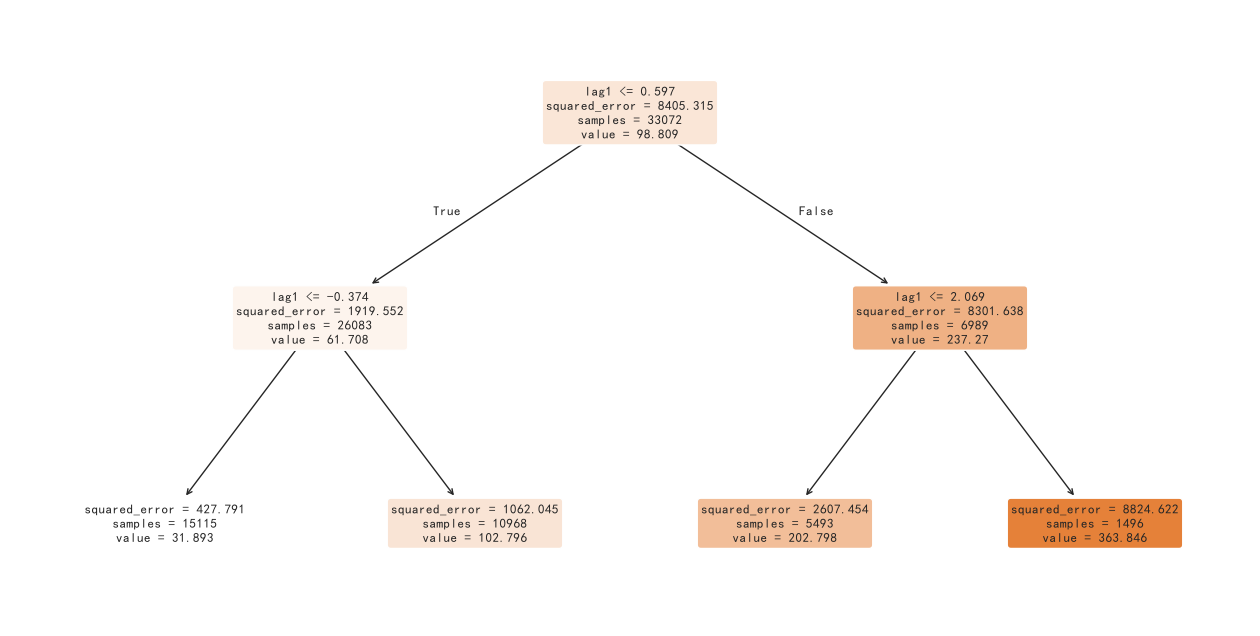

In [11]:
t_vis = DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE)
t_vis.fit(Xtr_pre, ytrain)

plt.figure(figsize=(16, 8))
plot_tree(t_vis,
          feature_names=[n.split('__')[-1] for n in pre_all.get_feature_names_out()],
          filled=True, rounded=True, fontsize=9)
plt.show()

# 三、Bagging 与随机森林

**对应 D8（10-20）· 约 3h · 常规**

单棵树的缺点是方差大，训练数据稍微变一点，整棵树的结构就变了。Bagging 的思路是种很多棵树然后平均，让各自的错误互相抵消。

随机森林在 Bagging 上再加一层随机，每次分裂时只看随机的一部分特征。这让树之间更不相似，平均起来效果更好。

这一章的重点不是调参，是搞清楚为什么平均能降方差。

## 3.1 先看单棵树有多不稳定

同一份数据，只换 `random_state`

用 `max_depth=8` 训 10 棵不同种子的树，把 10 个 R² 打印出来看范围。

In [12]:
seeds = range(10)
scores = []

for s in seeds:
    m = DecisionTreeRegressor(max_depth=8, random_state=s)
    m.fit(Xtr_pre, ytrain)
    scores.append(r2_score(ytest, m.predict(Xte_pre)))

print('单棵树 R2:', np.round(scores, 4))
print('均值 %.4f  标准差 %.4f  最差 %.4f  最好 %.4f'
      % (np.mean(scores), np.std(scores), min(scores), max(scores)))
print('波动幅度 %.4f' % (max(scores) - min(scores)))

单棵树 R2: [0.9268 0.9236 0.9247 0.9215 0.9246 0.9247 0.926  0.9258 0.9261 0.9266]
均值 0.9250  标准差 0.0015  最差 0.9215  最好 0.9268
波动幅度 0.0053


## 3.2 Bagging：并行种树再平均

`BaggingRegressor` 每棵树用有放回抽样（bootstrap）得到的子集训练，最后把所有树的预测取平均。


In [40]:
bag10 = make_pipeline(pre_all, BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
    n_estimators=10, max_samples=1.0, n_jobs=-1, random_state=RANDOM_STATE))
bag10_rmse = np.sqrt(mean_squared_error(ytest, bag10.fit(Xtrain, ytrain).predict(Xtest)))
bag10_score = r2_score(ytest, bag10.predict(Xtest))

bag50 = make_pipeline(pre_all, BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
    n_estimators=50, max_samples=1.0, n_jobs=-1, random_state=RANDOM_STATE))
bag50_rmse = np.sqrt(mean_squared_error(ytest, bag50.fit(Xtrain, ytrain).predict(Xtest)))
bag50_score = r2_score(ytest, bag50.predict(Xtest))

print('单棵树 depth=8  ', scores[0], 0)
print('Bagging 10棵    ', bag10_rmse, bag10_score)
print('Bagging 50棵    ', bag50_rmse, bag50_score)

单棵树 depth=8   0.9267809174940492 0
Bagging 10棵     22.941318229377885 0.9398312726069438
Bagging 50棵     22.714317020161 0.941016104260274


## 3.3 随机森林：Bagging + 特征随机

`RandomForestRegressor` 在 Bagging 的基础上，每次分裂时只在随机的 `max_features` 个特征里找切点。

- `n_estimators`：树的数量，越多越稳但收益递减，50~300 一般够。
- `max_features`：每次分裂考虑几个特征。回归默认 `1.0`（全部），分类默认 `sqrt`。设成 `0.3` 或 `sqrt` 会强制增加树之间的差异。

In [14]:
rf = make_pipeline(pre_all, RandomForestRegressor(
    n_estimators=100, max_features=0.3, n_jobs=-1, random_state=RANDOM_STATE))
rf.fit(Xtrain, ytrain)
rf_rmse = np.sqrt(mean_squared_error(ytest, rf.predict(Xtest)))
rf_score = r2_score(ytest, rf.predict(Xtest))

rf_all = make_pipeline(pre_all, RandomForestRegressor(
    n_estimators=100, max_features=1.0, n_jobs=-1, random_state=RANDOM_STATE))
rf_all.fit(Xtrain, ytrain)
rf_all_rmse = np.sqrt(mean_squared_error(ytest, rf_all.predict(Xtest)))
rf_all_score = r2_score(ytest, rf_all.predict(Xtest))

print('Bagging 50棵      ', bag50_rmse, bag50_score)
print('随机森林 mf=1.0   ', rf_all_rmse, rf_all_score)
print('随机森林 mf=0.3   ', rf_rmse, rf_score)

Bagging 50棵       22.714317020161 0.941016104260274
随机森林 mf=1.0    22.489061314627385 0.9421801787748241
随机森林 mf=0.3    21.231154557182386 0.9484674882135533


## 3.4 树的数量与收益递减

`n_estimators` 从 10 到 300，看测试集 R² 怎么变。

理论上随着树的增加，泛化误差会单调下降然后收敛，不会因为树多而过拟合。


In [15]:
n_list = [10, 30, 50, 100, 200, 300]
n_rmse = []
n_score = []

for n in n_list:
    m = make_pipeline(pre_all, RandomForestRegressor(
        n_estimators=n, max_features=0.3, n_jobs=-1, random_state=RANDOM_STATE))
    m.fit(Xtrain, ytrain)
    p = m.predict(Xtest)
    n_rmse.append(round(np.sqrt(mean_squared_error(ytest, p)), 3))
    n_score.append(round(r2_score(ytest, p), 4))

n_df = pd.DataFrame({'树的数量': n_list, 'RMSE': n_rmse, 'R2': n_score})
n_df

,树的数量,RMSE,R2
0,10,23.368,0.9376
1,30,21.789,0.9457
2,50,21.548,0.9469
3,100,21.231,0.9485
4,200,21.163,0.9488
5,300,21.116,0.9490


## 3.5 随机森林的特征重要度 vs 单棵树

随机森林的重要度是所有树的重要度平均，比单棵树稳定得多。两次换种子跑，单棵树的重要度会变，随机森林的基本不变。

把两边的 top8 并排打印出来对比。

In [41]:
names_rf = pre_all.get_feature_names_out()
imp_rf = rf.named_steps['randomforestregressor'].feature_importances_

cmp_imp = pd.DataFrame({'特征': [n.split('__')[-1] for n in names_rf],
                        '单棵树': np.round(imp_deep, 4),
                        '随机森林': np.round(imp_rf, 4)})
cmp_imp = cmp_imp.sort_values('随机森林', ascending=False).head(8)
cmp_imp

,特征,单棵树,随机森林
0,lag1,0.9607,0.4873
2,roll_mean_3,0.0088,0.3019
3,roll_mean_24,0.0045,0.0873
4,roll_std_24,0.0029,0.0308
1,lag24,0.0018,0.0205
10,Iws,0.0036,0.0178
7,DEWP,0.0062,0.0167
8,TEMP,0.0019,0.0088


## D8


### 感想

Bagging 能够降低方差，这是通过多棵树并行使得特殊情况对单棵树的影响得到平均，从而减小方差。这里降的只是方差，偏差并没有降，所以树加再多，分数涨到某个上限就上不去了。

随机森林比 Bagging 多了 `max_features`，这一点使得树与树之间的重复度降低了，从个人感觉来说像是让树朝着原本较少考虑的方向生长，进而在原本 Bagging 的基础上继续降低方差。

在随机森林中，随着树的增多，方差的影响被多棵树取平均值这个步骤大大降低了，但虽然我们尽可能的用 `max_features` 去使树生长的方向不一致，但树与树之间还是有关联的。

随机森林在防过拟合上确实不用靠 `max_depth`，多棵树平均已经把单棵树的方差的影响减小了。但在实际使用中还是值得设一下，不然模型会让一棵树会一直长到叶子只剩一个样本，慢而且占内存。



# 四、模型对比与残差分析

**对应 D9（10-21）· 约 3h · 常规**

到这一步手上已经有 6 个模型：线性回归、KNN、决策树、Bagging、随机森林，加上两条基线。
看看不用模型的优缺点与未来方向

## 4.1 汇总表：模型 × 指标

把前面所有 `evaluate` 的返回值拼成一张表，按 RMSE 排序，并算每个模型相对基线的差距。


In [42]:
linear = make_pipeline(pre_all, LinearRegression())
linear.fit(Xtrain, ytrain)
lin_rmse = np.sqrt(mean_squared_error(ytest, linear.predict(Xtest)))
lin_score = r2_score(ytest, linear.predict(Xtest))

knn100 = make_pipeline(pre_all, KNeighborsRegressor(n_neighbors=100))
knn100.fit(Xtrain, ytrain)
knn_rmse = np.sqrt(mean_squared_error(ytest, knn100.predict(Xtest)))
knn_score = r2_score(ytest, knn100.predict(Xtest))

print('基线      ', Baseline_rmse, Baseline_score)
print('线性回归  ', lin_rmse, lin_score)
print('KNN k=100  ', knn_rmse, knn_score)
print('决策树    ', dt_rmse, dt_score)
print('随机森林  ', rf_rmse, rf_score)

基线       22.136457386885123 0.9439790683721084
线性回归   21.22787569671545 0.9484834039630068
KNN k=100   28.029460361938888 0.9101819627013903
决策树     23.845214656716568 0.934996527079134
随机森林   21.231154557182386 0.9484674882135533


## 4.2 残差分布

残差 = 真实值 − 预测值。

残差直方图看分布形态、预测值 vs 残差散点看有没有喇叭形或曲线、真实值分档后的平均残差看模型在哪一档系统性偏差最大。


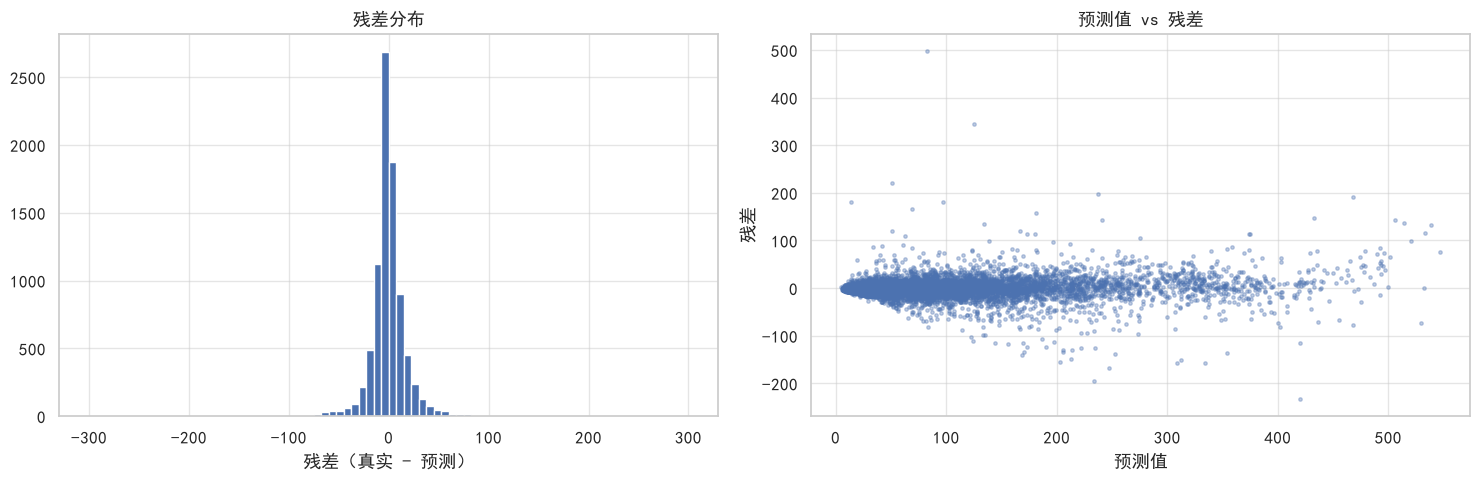

In [43]:
p_rf = rf.predict(Xtest)
resid = ytest.values - p_rf

fig, axes = plt.subplots(1,2, figsize=(15, 5))
axes[0].hist(resid, bins=80, range=(-300, 300))
axes[0].set_xlabel('残差（真实 - 预测）')
axes[0].set_title('残差分布')
axes[1].scatter(p_rf, resid, s=6, alpha=.35)
axes[1].set_xlabel('预测值')
axes[1].set_ylabel('残差')
axes[1].set_title('预测值 vs 残差')
plt.tight_layout()
plt.show()

## 4.3 按真实值分档看偏差

把测试集的真实 pm2.5 按分位数切成 5 档，每档算平均真实值、平均预测值、平均残差。

低档残差为正、高档残差为负，就是典型的向均值回归，模型不敢预测极端值。树模型和线性回归都有这个倾向，只是程度不同。

In [44]:
bins = pd.qcut(test['pm2.5'], 5, labels=False)
bucket = pd.DataFrame({'真实': ytest.values, '预测': p_rf, '档': bins}).groupby('档').agg(
    真实均值=('真实', 'mean'), 预测均值=('预测', 'mean'), 条数=('真实', 'size'))
bucket['平均残差'] = (bucket['真实均值'] - bucket['预测均值']).round(1)
bucket.round(1)

,真实均值,预测均值,条数,平均残差
档,,,,
0,13.1,17.7,1786,-4.7
1,37.6,42.3,1693,-4.7
2,72.0,75.0,1728,-3.0
3,118.2,117.3,1744,0.9
4,250.8,241.2,1710,9.6


## 4.4 分月误差：漂移有多严重

W3 发现 2013-01 的月均 193.3、2014-06 只有 59.1。同一个模型在污染重的月份和清洁月份表现完全不同，这是时序数据特有的问题。

按月算 RMSE，和月均浓度放一起看。

In [45]:
monthly = (pd.DataFrame({'真实': ytest.values, '预测': p_rf}, index=test.index).resample('ME').agg (                                                                                                                                            {'真实': 'mean', '预测': 'mean'}))
monthly['RMSE'] = pd.Series((ytest.values - p_rf)**2, index=test.index).resample('ME').mean().pow(0.5)
monthly.round(1)

,真实,预测,RMSE
datetime,,,
2014-01-31,118.6,115.7,34.2
2014-02-28,174.6,171.0,26.5
2014-03-31,110.5,110.4,21.0
2014-04-30,95.2,96.2,25.5
2014-05-31,72.3,73.1,18.3
2014-06-30,59.1,61.0,14.4
2014-07-31,89.5,90.1,13.7
2014-08-31,62.9,65.5,15.2
2014-09-30,70.3,72.9,14.3


In [46]:
feats_diff = feats.copy()
feats_diff['diff'] = feats_diff['pm2.5'] - feats_diff['lag1']

corr = feats_diff[num_all + ['diff']].corr()['diff'].drop(['diff','lag1']).sort_values()
corr_df = corr.to_frame('与变化量的相关性')
print(corr_df.round(4))
print()
print('变化量标准差 %.2f  pm2.5 标准差 %.2f' % (feats_diff['diff'].std(), feats_diff['pm2.5'].std()))
print('相关性绝对值最大 %.4f' % corr.abs().max())

              与变化量的相关性
roll_mean_3            -0.1642
roll_mean_24           -0.1137
hour_sin               -0.0896
roll_std_24            -0.0768
lag24                  -0.0552
Ir                     -0.0256
TEMP                   -0.0091
Iws                    -0.0081
Is                      0.0031
DEWP                    0.0051
PRES                    0.0055
hour_cos                0.0366

变化量标准差 24.53  pm2.5 标准差 92.07
相关性绝对值最大 0.1642


## D9


### 感想

残差整体看起来接近正态分布，但按浓度分档后，浓度越高残差越散——五档的标准差从 9.07 一路涨到 39.00，低档残差为负，高档残差为正，这是因为模型不敢于去预测较为极端的值。


lag1这个特征与对下一小时的预测相关性太强了，而线性回归与KNN在预测过程中不完全依靠这一特征，而树主要就依靠最有区分度的特征去进行划分，主要靠lag1，且在其他特征的帮助下才能超过持久性基线。

模型随着PM2.5的浓度上升预测准确度下降，并且缺乏对于连续月份之间关联的思考能力。误差跟着浓度走



# 五、★ Boosting：AdaBoost / GBDT / XGBoost

**对应 D10（10-22）· 3.5–4.5h · 硬骨头**

Bagging 是并行种很多棵树再平均，树与树之间互不干扰。Boosting 正好相反，串行种树，每棵新树在前面的基础上再次发展。

> Bagging 降低的是方差，多个独立模型平均，噪声抵消。
> Boosting 降低的是偏差，一步步逼近，每一步都针对当前的不足。


## 5.1 Boosting 的基本循环

在 sklearn 之前，先手写一遍最原始的 Boosting，

流程是：先给所有样本一个初始预测（均值），算出每个样本的残差，用一棵小树去拟合残差（拟合的是残差，不是原始 y），把这棵树的预测乘上学习率加到已有预测上，回到第二步。

`learning_rate` 越小每一步只敢走一点点，需要更多轮次；太大会一步走过头。

In [53]:
X_b = Xtr_pre
y_b = ytrain.values

pred_b = np.full(len(y_b), y_b.mean())
lr_boost = 0.1

for step in range(30):
    resid_b = y_b - pred_b
    stump = DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE)
    stump.fit(X_b, resid_b)
    pred_b = pred_b + lr_boost*stump.predict(X_b)
    if step < 5 or step == 29:
        print('第 %2d 棵 训练 RMSE = %.2f' % (step+1, np.sqrt(mean_squared_error(y_b, pred_b))))

第  1 棵 训练 RMSE = 84.09
第  2 棵 训练 RMSE = 77.34
第  3 棵 训练 RMSE = 71.24
第  4 棵 训练 RMSE = 65.83
第  5 棵 训练 RMSE = 60.89
第 30 棵 训练 RMSE = 25.53


看训练 RMSE 的变化，每一步都在下降，而且下降幅度越来越小。这就是 Boosting 的工作方式，一棵树不够，再来一棵专门补它的错。

这也是它天然能做残差建模的原因：它每一步都在拟合残差。D9 发现真正难预测的是变化量，Boosting 的机制天生就在做这件事。

## 5.2 AdaBoost

Boosting 最早的实用版本，思路是调样本权重：上一轮被判错的样本，下一轮权重变大，逼后一棵树重点关注它们。

优点是不太需要调参，缺点是对噪声敏感。样本里有标错或极端离群值时，权重会越滚越大，最后模型去死磕那几个不可能对的点。

跑一个 `AdaBoostRegressor`，`n_estimators=100`，看结果。

In [48]:
ada30 = make_pipeline(pre_all, AdaBoostRegressor(
    n_estimators=30, learning_rate=0.5, random_state=RANDOM_STATE))
ada30.fit(Xtrain, ytrain)
ada30_rmse = np.sqrt(mean_squared_error(ytest, ada30.predict(Xtest)))
ada30_score = r2_score(ytest, ada30.predict(Xtest))

ada100 = make_pipeline(pre_all, AdaBoostRegressor(
    n_estimators=100, random_state=RANDOM_STATE))
ada100.fit(Xtrain, ytrain)
ada100_rmse = np.sqrt(mean_squared_error(ytest, ada100.predict(Xtest)))
ada100_score = r2_score(ytest, ada100.predict(Xtest))

print('随机森林        ', rf_rmse, rf_score)
print('AdaBoost 30棵   ', ada30_rmse, ada30_score)
print('AdaBoost 100棵  ', ada100_rmse, ada100_score)

随机森林         21.231154557182386 0.9484674882135533
AdaBoost 30棵    27.605872192254925 0.9128761550480395
AdaBoost 100棵   61.854279192721904 0.5626052277037089


## 5.3 GBDT：梯度提升决策树

`GradientBoostingRegressor` 是 Boosting 的主流实现。它和 AdaBoost 的区别是不调样本权重，而是直接拟合损失函数的负梯度，平方损失下就是残差。

- `n_estimators`：树的数量，也就是 boosting 轮数。
- `learning_rate`：每棵树的贡献缩放，和 `n_estimators` 此消彼长，lr 减半树数通常要翻倍。
- `max_depth`：每棵树多深。Boosting 的树通常是浅树（3~5），每棵只负责修正一点点。

In [54]:
gbdt = make_pipeline(pre_all, GradientBoostingRegressor(
    n_estimators=200, learning_rate=0.05, max_depth=4,
    subsample=0.8, random_state=RANDOM_STATE))
gbdt.fit(Xtrain, ytrain)
gbdt_rmse = np.sqrt(mean_squared_error(ytest, gbdt.predict(Xtest)))
gbdt_score = r2_score(ytest, gbdt.predict(Xtest))

gbdt_deep = make_pipeline(pre_all, GradientBoostingRegressor(
    n_estimators=200, learning_rate=0.1, max_depth=8, random_state=RANDOM_STATE))
gbdt_deep.fit(Xtrain, ytrain)
gbdt_deep_rmse = np.sqrt(mean_squared_error(ytest, gbdt_deep.predict(Xtest)))
gbdt_deep_score = r2_score(ytest, gbdt_deep.predict(Xtest))

print('GBDT lr=0.05 depth=4  ', gbdt_rmse, gbdt_score)
print('GBDT lr=0.1  depth=8  ', gbdt_deep_rmse, gbdt_deep_score)

GBDT lr=0.05 depth=4   21.196672976962304 0.9486347404919783
GBDT lr=0.1  depth=8   22.62469128236045 0.9414806610885231


## 5.4 learning_rate 与 n_estimators 的权衡

固定 `n_estimators=200`，扫 `learning_rate` 从 0.01 到 0.5，看测试集 R²。

预期是一条先升后平的曲线：lr 太小则 200 棵树不够收敛，太大则单棵树走过头产生过拟合。

`GradientBoostingRegressor` 比较慢，这组扫描要跑一两分钟。

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


耗时 67.9 秒


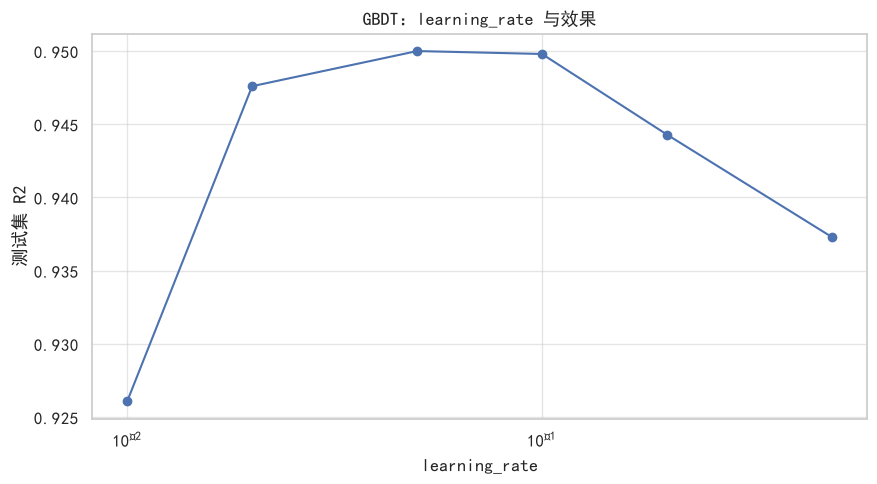

,learning_rate,RMSE,R2
0,0.01,25.431,0.9261
1,0.02,21.401,0.9476
2,0.05,20.910,0.9500
3,0.10,20.949,0.9498
4,0.20,22.081,0.9443
5,0.50,23.422,0.9373


In [50]:
lr_list = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
lr_rmse = []
lr_score = []

t0 = time.time()
for lr in lr_list:
    m = make_pipeline(pre_all, GradientBoostingRegressor(
        n_estimators=200, learning_rate=lr, max_depth=4, random_state=RANDOM_STATE))
    m.fit(Xtrain, ytrain)
    p = m.predict(Xtest)
    lr_rmse.append(round(np.sqrt(mean_squared_error(ytest, p)), 3))
    lr_score.append(round(r2_score(ytest, p), 4))
print('耗时 %.1f 秒' % (time.time()-t0))

plt.plot(lr_list, lr_score, 'o-')
plt.xscale('log')
plt.xlabel('learning_rate')
plt.ylabel('测试集 R2')
plt.title('GBDT：learning_rate 与效果')
plt.show()

lr_df = pd.DataFrame({'learning_rate': lr_list, 'RMSE': lr_rmse, 'R2': lr_score})
lr_df

## 5.5 XGBoost

XGBoost 相比 GBDT 的几处改进：用到了二阶导数（Hessian），收敛更快；目标函数里显式加了叶子权重和叶子数的惩罚，天然抗过拟合；借鉴随机森林做了列采样和行采样；缺失值自动学一个默认分裂方向。

它的参数体系和 sklearn 不同，最常见的是 `n_estimators`、`learning_rate`、`max_depth`、`subsample`、`colsample_bytree`、`reg_lambda`。
（z

In [51]:
from xgboost import XGBRegressor

xgb = make_pipeline(pre_all, XGBRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    n_jobs=-1, random_state=RANDOM_STATE))
xgb.fit(Xtrain, ytrain)
xgb_rmse = np.sqrt(mean_squared_error(ytest, xgb.predict(Xtest)))
xgb_score = r2_score(ytest, xgb.predict(Xtest))

print('GBDT            ', gbdt_rmse, gbdt_score)
print('XGBoost 500棵   ', xgb_rmse, xgb_score)

GBDT             21.196672976962304 0.9486347404919783
XGBoost 500棵    21.30438897885663 0.9481113641415281


## 5.6 Boosting 家族汇总

把 AdaBoost、GBDT、XGBoost 和前面所有模型排在一张表里，看 Boosting 到底有没有打败持久性基线。

In [52]:
boost_rows = [
    ['持久性基线', round(Baseline_rmse, 3), round(Baseline_score, 4)],
    ['线性回归', round(lin_rmse, 3), round(lin_score, 4)],
    ['KNN k=98', round(knn_rmse, 3), round(knn_score, 4)],
    ['决策树', round(dt_rmse, 3), round(dt_score, 4)],
    ['随机森林', round(rf_rmse, 3), round(rf_score, 4)],
    ['AdaBoost 30棵', round(ada30_rmse, 3), round(ada30_score, 4)],
    ['AdaBoost 100棵', round(ada100_rmse, 3), round(ada100_score, 4)],
    ['GBDT', round(gbdt_rmse, 3), round(gbdt_score, 4)],
    ['XGBoost', round(xgb_rmse, 3), round(xgb_score, 4)],
]
boost_df = pd.DataFrame(boost_rows, columns=['模型', 'RMSE', 'R2'])
boost_df['比基线差'] = (boost_df['RMSE'] - Baseline_rmse).round(3)
boost_df['打败基线'] = boost_df['RMSE'] < Baseline_rmse
boost_df

,模型,RMSE,R2,比基线差,打败基线
0,持久性基线,22.136,0.9440,-0.000,True
1,线性回归,21.228,0.9485,-0.908,True
2,KNN k=98,28.029,0.9102,5.893,False
3,决策树,23.845,0.9350,1.709,False
4,随机森林,21.231,0.9485,-0.905,True
5,AdaBoost 30棵,27.606,0.9129,5.470,False
6,AdaBoost 100棵,61.854,0.5626,39.718,False
7,GBDT,21.197,0.9486,-0.939,True
8,XGBoost,21.304,0.9481,-0.832,True


## D10

### 感想

1.Boosting和Bagging在训练方式上最根本的区别在于Bagging的每一棵树之间互不影响，通过树的数量来减小偶然的方差，而Boosting中每一棵树都是在前一棵树的基础上上继续迭代，通过迭代来减小偏差

2.Boosting就像是一小步一小步的优化，如果树太深的话产生过拟合对后续迭代的树产生的影响较大，而Bagging虽然走的远，方向也由于噪声在每棵树上都造成了方差，但多棵树取平均又很大程度上减小了方差，所以Bagging的树可以很深

3.learning_rate与n_estimators的关系就像每一步的距离与步数的关系，步距太大容易跑过，感觉实际运用之中优先取小learning_rate

4.AdaBoosting在修正错误的方式是在迭代过程中不断加重判断错误的样本的权重，而GBDT就是将label与pred之间的差值拟合为一个损失函数，进而用梯度下降不断找到最快减小损失函数的方向


# 六、★ 随机调参 / 时序 CV / 模型融合

**对应 D11（10-23）· 3.5–4.5h · 硬骨头**

最后一天做三件事：**把模型的参数调好、把调参过程做对、把多个模型合起来。**


## 6.1 网格搜索 vs 随机搜索

`GridSearchCV` 把所有组合都试一遍，参数量一大就爆炸，网格搜索把大量算力浪费在无关参数的组合上。

用 GBDT 演示两者：同样跑 20 次，看随机搜索找到的最好分数和网格搜索差多少。

In [55]:
tscv = TimeSeriesSplit(n_splits=3)

grid = GridSearchCV(
    make_pipeline(pre_all, GradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_grid={'gradientboostingregressor__max_depth': [3, 4, 6],
                'gradientboostingregressor__learning_rate': [0.05, 0.1],
                'gradientboostingregressor__n_estimators': [100, 200]},
    cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=-1)

t0 = time.time()
grid.fit(Xtrain, ytrain)
print('网格搜索 %d 组，耗时 %.1f 秒' % (len(grid.cv_results_['params']), time.time()-t0))
print(grid.best_params_)
print('最好 CV RMSE = %.4f' % (-grid.best_score_))

网格搜索 12 组，耗时 36.6 秒
{'gradientboostingregressor__learning_rate': 0.05, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__n_estimators': 100}
最好 CV RMSE = 25.1315


## 6.2 RandomizedSearchCV：用分布去搜

`randint(low, high)` 是整数均匀分布，`uniform(loc, scale)` 是浮点均匀分布，`loguniform` 是对数均匀分布。

`loguniform` 适合 `learning_rate` 这种跨数量级的参数，直接均匀采样会把一半算力花在 0.5~1.0 这种不合理的区间。

In [56]:
rand_search = RandomizedSearchCV(
    make_pipeline(pre_all, GradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_distributions={
        'gradientboostingregressor__n_estimators': randint(150, 400),
        'gradientboostingregressor__learning_rate': loguniform(0.03, 0.15),
        'gradientboostingregressor__max_depth': randint(3, 6),
        'gradientboostingregressor__min_samples_leaf': randint(10, 60),
        'gradientboostingregressor__subsample': uniform(0.7, 0.3),
    },
    n_iter=25, cv=tscv, scoring='neg_root_mean_squared_error',
    n_jobs=-1, random_state=RANDOM_STATE)

t0 = time.time()
rand_search.fit(Xtrain, ytrain)
print('随机搜索 25 组，耗时 %.1f 秒' % (time.time()-t0))
print(rand_search.best_params_)
print('最好 CV RMSE = %.4f' % (-rand_search.best_score_))


随机搜索 25 组，耗时 64.7 秒
{'gradientboostingregressor__learning_rate': np.float64(0.03497921543472225), 'gradientboostingregressor__max_depth': 5, 'gradientboostingregressor__min_samples_leaf': 32, 'gradientboostingregressor__n_estimators': 211, 'gradientboostingregressor__subsample': np.float64(0.7975549966080241)}
最好 CV RMSE = 23.7136


## 6.3 CV 分数为什么不等于测试分数

CV 找到的最好 RMSE 是 23.71，拿到 2014 测试集上却是 20.86，CV 反而更差。

每折训练数据更少，33072 条训练集切成 3 折，第一折只有约 1/4 的数据，自然更差。折与折之间差异也大，2013 年内不同时段的污染水平差很多。而 CV 分数是平均，测试集是一个具体的、可能偏难的年份。

把每一折的分数单独打出来看分布

25 组 CV RMSE 范围: 23.71 ~ 24.74
标准差 0.2366


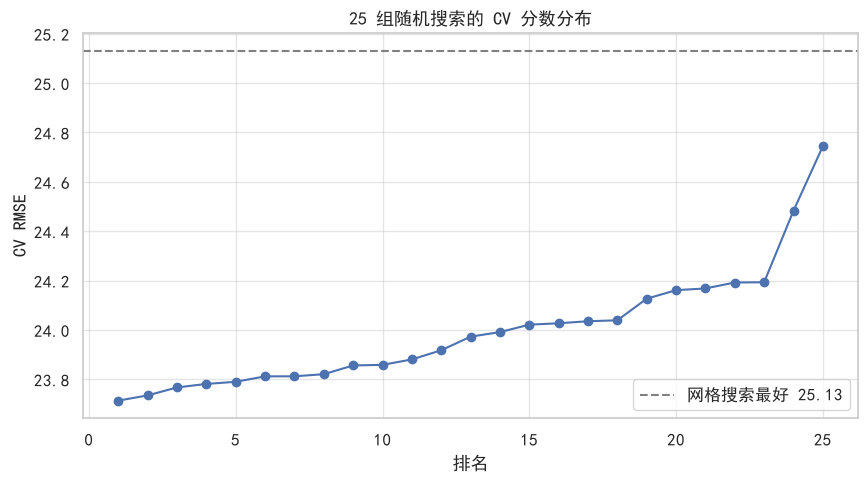

In [57]:
cv_rmse = -rand_search.cv_results_['mean_test_score']
print('25 组 CV RMSE 范围: %.2f ~ %.2f' % (cv_rmse.min(), cv_rmse.max()))
print('标准差 %.4f' % cv_rmse.std())

plt.plot(range(1, 26), np.sort(cv_rmse), 'o-')
plt.axhline(-grid.best_score_, color='gray', ls='--',
            label='网格搜索最好 %.2f' % (-grid.best_score_))
plt.xlabel('排名')
plt.ylabel('CV RMSE')
plt.title('25 组随机搜索的 CV 分数分布')
plt.legend()
plt.show()


## 6.4 用调好的参数在测试集上评估

`rand_search.best_estimator_` 是已经 fit 好的完整 Pipeline，可以直接 predict。为了和前面的模型口径一致，这里重新 evaluate 一次。


In [35]:
tuned = rand_search.best_estimator_
tuned_rmse = np.sqrt(mean_squared_error(ytest, tuned.predict(Xtest)))
tuned_score = r2_score(ytest, tuned.predict(Xtest))

print('GBDT ', gbdt_rmse, gbdt_score)
print('GBDT 调参后', tuned_rmse, tuned_score)


GBDT  21.196672976962304 0.9486347404919783
GBDT 调参后 20.856449998761036 0.9502704116003812


## 6.5 模型融合：平均法

融合的想法是让不同模型的错误互相抵消，前提是模型之间要足够不同。同样两个线性回归平均起来毫无意义。

两种最常见的做法：简单平均 `(a + b + c) / 3`，稳健不容易翻车；加权平均，给表现好的模型更大权重，权重可以在验证集上搜。

参与融合的模型最好来自不同家族：线性回归、KNN、随机森林、GBDT。

In [32]:
pred_lr = linear.predict(Xtest)
pred_rf = rf.predict(Xtest)
pred_gb = tuned.predict(Xtest)

def blend_scores(name, p):
    return [name, round(np.sqrt(mean_squared_error(ytest, p)), 3), round(r2_score(ytest, p), 4)]

blend_rows = []
blend_rows.append(blend_scores('线性回归', pred_lr))
blend_rows.append(blend_scores('随机森林', pred_rf))
blend_rows.append(blend_scores('GBDT 调参后', pred_gb))
blend_rows.append(blend_scores('平均 LR+RF+GB', (pred_lr+pred_rf+pred_gb)/3))
blend_rows.append(blend_scores('平均 RF+GB', (pred_rf+pred_gb)/2))
blend_rows.append(blend_scores('加权 0.2/0.4/0.4', pred_lr*0.2+pred_rf*0.4+pred_gb*0.4))

blend_df = pd.DataFrame(blend_rows, columns=['模型', 'RMSE', 'R2'])
blend_df


,模型,RMSE,R2
0,线性回归,21.228,0.9485
1,随机森林,21.231,0.9485
2,GBDT 调参后,20.856,0.9503
3,平均 LR+RF+GB,20.674,0.9511
4,平均 RF+GB,20.765,0.9507
5,加权 0.2/0.4/0.4,20.681,0.9511


## 6.6 融合值不值得



| 模型 | RMSE |
| --- | --- |
| 线性回归 | 21.228 |
| 随机森林 | 21.231 |
| GBDT 调参后 | 20.856 |
| 平均 LR+RF+GB | 20.674 |
| 平均 RF+GB | 20.765 |
| 加权 0.2/0.4/0.4 | 20.681 |



融合基本失效了：平均只好了 0.87%，加权也只好了 0.84%

从误差的角度，这三个模型的误差原因相似，导致三个模型融合以后误差仍然存在难以避免
从改进的角度，这三个模型在一轮一轮的升级中快接近极限了，接下来的改进应该不是通过换模型能解决的


**结论：融合应该尝试在模型差异较大的时候尝试去做

可惜这次没做出来对两个差异较大的模型通过融合具体能得到多少改进，包括融合中各部分权重如何判断后续也需要继续学习


In [33]:
best_single = min(lin_rmse, rf_rmse, tuned_rmse)
print('最好单模型 RMSE = %.3f' % best_single)

avg3 = (pred_lr+pred_rf+pred_gb)/3
avg2 = (pred_rf+pred_gb)/2

print('平均 LR+RF+GB  RMSE %.3f  相对提升 %.2f%%' % (
    np.sqrt(mean_squared_error(ytest, avg3)),
    (best_single - np.sqrt(mean_squared_error(ytest, avg3)))/best_single*100))
print('平均 RF+GB     RMSE %.3f  相对提升 %.2f%%' % (
    np.sqrt(mean_squared_error(ytest, avg2)),
    (best_single - np.sqrt(mean_squared_error(ytest, avg2)))/best_single*100))
print()

最好单模型 RMSE = 20.856
平均 LR+RF+GB  RMSE 20.674  相对提升 0.87%
平均 RF+GB     RMSE 20.765  相对提升 0.44%



## 6.7 A 换一个建模对象：预测变化量

D9 发现所有模型都在向均值回归，真正的难点是变化量。下面直接验证这个想法。

做法是目标改成 `diff = pm2.5 - lag1`，模型只预测下一小时相对当前小时会变多少，最后把预测加回 `lag1` 得到绝对值。

模型上变化很小了，就换方向

In [58]:
ytr_diff = (train['pm2.5'] - train['lag1']).values
yte_diff = (test['pm2.5'] - test['lag1']).values

gb_diff = make_pipeline(pre_all, GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=4,
    subsample=0.8, random_state=RANDOM_STATE))
gb_diff.fit(Xtrain, ytr_diff)

p_diff = gb_diff.predict(Xtest)
p_abs = test['lag1'].values + p_diff

print('预测 diff: 均值 %.2f  标准差 %.2f' % (p_diff.mean(), p_diff.std()))
print('真实 diff: 均值 %.2f  标准差 %.2f' % (yte_diff.mean(), yte_diff.std()))
print()
print('直接预测绝对值  ', round(np.sqrt(mean_squared_error(ytest, pred_gb)), 3), round(r2_score(ytest, pred_gb), 4))
print('预测变化量再加回', round(np.sqrt(mean_squared_error(ytest, p_abs)), 3), round(r2_score(ytest, p_abs), 4))
print('持久性基线      ', round(Baseline_rmse, 3), round(Baseline_score, 4))


预测 diff: 均值 -0.03  标准差 10.04
真实 diff: 均值 -0.00  标准差 22.14

直接预测绝对值   20.856 0.9503
预测变化量再加回 20.816 0.9505
持久性基线       22.136 0.944


## 6.7 B 同一件事，但把树变浅

上一节 `max_depth=4` 的结果做出来是 21.746，比原来（20.856）还差。

但是在调节了几次树的迭代层数以后，发现应该是过拟合了

In [59]:
gb_diff_shallow = make_pipeline(pre_all, GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=2,
    subsample=0.8, random_state=RANDOM_STATE))
gb_diff_shallow.fit(Xtrain, ytr_diff)

p_diff_shallow = gb_diff_shallow.predict(Xtest)

print('max_depth=4  diff 自身 R2 %.4f' % r2_score(yte_diff, p_diff))
print('max_depth=2  diff 自身 R2 %.4f' % r2_score(yte_diff, p_diff_shallow))
print()
print('预测 diff 标准差   深度4 %.2f   深度2 %.2f   （真实 %.2f）' % (
    p_diff.std(), p_diff_shallow.std(), yte_diff.std()))
print()

diff_rows = []
for name, pd_ in [('depth=4', p_diff), ('depth=2', p_diff_shallow)]:
    for alpha in [0.0, 0.4, 0.6, 1.0]:
        p = test['lag1'].values + pd_ * alpha
        diff_rows.append([name, alpha,
                          round(np.sqrt(mean_squared_error(ytest, p)), 3),
                          round(r2_score(ytest, p), 4)])

diff_df = pd.DataFrame(diff_rows, columns=['树深', 'alpha', 'RMSE', 'R2'])
diff_df


max_depth=4  diff 自身 R2 0.1157
max_depth=2  diff 自身 R2 0.0884

预测 diff 标准差   深度4 10.04   深度2 7.53   （真实 22.14）



,树深,alpha,RMSE,R2
0,depth=4,0.0,22.136,0.9440
1,depth=4,0.4,21.051,0.9493
2,depth=4,0.6,20.780,0.9506
3,depth=4,1.0,20.816,0.9505
4,depth=2,0.0,22.136,0.9440
5,depth=2,0.4,21.426,0.9475
6,depth=2,0.6,21.223,0.9485
7,depth=2,1.0,21.136,0.9489


## 6.8 D11 收尾

同一个想法，`depth=4` 得到 21.746，`depth=2` 得到 21.136
但其中具体原理还在理解中

# 七、本周小结与结果记录

**对应 D11 收尾 · 顺带为 D13-D14 的端到端项目准备素材**

## 7.1 回归任务结果表

| 模型 | 特征 | 划分方式 | RMSE | R² | 备注 |
| --- | --- | --- | --- | --- | --- |
| 均值基线 | 无 | 时序 | 93.532 | 0.0000 | 永远猜训练集平均 |
| 持久性基线（lag1） | 无 | 时序 | 22.136 | 0.9440 | 最强基线 |
| 决策树 | 时序特征 | 时序 | 23.845 | 0.9350 | depth=4，D7 |
| Bagging 10 棵 | 时序特征 | 时序 | 22.941 | 0.9398 | D8 |
| Bagging 50 棵 | 时序特征 | 时序 | 22.714 | 0.9410 | D8 |
| 随机森林 | 时序特征 | 时序 | 21.231 | 0.9485 | mf=0.3，D8 |
| 线性回归 | 时序特征 | 时序 | 21.228 | 0.9485 | D9 |
| KNN（k=100） | 时序特征 | 时序 | 28.029 | 0.9102 | W3，本数据上最差 |
| AdaBoost 30 棵 | 时序特征 | 时序 | 27.606 | 0.9129 | D10 |
| AdaBoost 100 棵 | 时序特征 | 时序 | 61.854 | 0.5626 | D10，崩了 |
| GBDT | 时序特征 | 时序 | 21.197 | 0.9486 | lr=0.05 depth=4，D10 |
| XGBoost | 时序特征 | 时序 | 21.304 | 0.9481 | D10 |
| GBDT（随机搜索调参后） | 时序特征 | 时序 | 20.856 | 0.9503 | D11，全周单模型最好 |
| 平均融合 LR+RF+GB | 时序特征 | 时序 | 20.674 | 0.9511 | D11，比最好单模型好 0.87% |
| 加权融合 0.2/0.4/0.4 | 时序特征 | 时序 | 20.681 | 0.9511 | D11 |
| GBDT 预测变化量（depth=4，alpha=0.6） | 时序特征 | 时序 | 20.780 | 0.9506 | D11 |
| GBDT 预测变化量（depth=2，alpha=1.0） | 时序特征 | 时序 | 21.136 | 0.9489 | D11 |


## 7.2 本周小结

### 1. 自己的一些想法
感觉印象最深的就是换模型与换研究对象的前后对比吧，在模型已经到达极限的的时候，一味的想去优化模型，倒不如结合真正的模型，看看转换研究对象，可能这一点的改变就可以事半功倍，切忌钻牛角尖
### 2. 踩过的坑
之前设计预处理的时候，pre的处理对象忘记把新添的特征lag1什么的加进去了，程序也不报错，pre少接收一列就直接默默丢掉了，搞得我后面好长一段时间觉得不对劲
还有这周的模型融合，LR+RF+GBDT 三个平均后 RMSE 20.674，比最好的单模型 20.856 只好了一点点（0.87%），本来想当然的觉得融合以后会比原来更好，忽视了这几个模型产生误差的原因都大差不差